# Chapter 4: Matrices as transformations

The code for this chapter from [*Matrices in Practice*](https://trgoodale.github.io/matrix-book/part-1/04-transformations.html), by Tom Goodale.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/trgoodale/matrix-book/blob/main/code/python/04-transformations.ipynb)

Run the cells in order, from the top: later cells use variables set in earlier ones. Change the numbers and run them again to see what happens. The code needs NumPy, SciPy and Matplotlib (and pandas in a few chapters), all of which Colab already has.

Code licensed under the [MIT licence](https://trgoodale.github.io/matrix-book/LICENSE.md).

### Code for Figure 4.1

This draws [Figure 4.1](https://trgoodale.github.io/matrix-book/part-1/04-transformations.html#fig-transformation-gallery) in the chapter. You don't need it for the rest of the notebook.

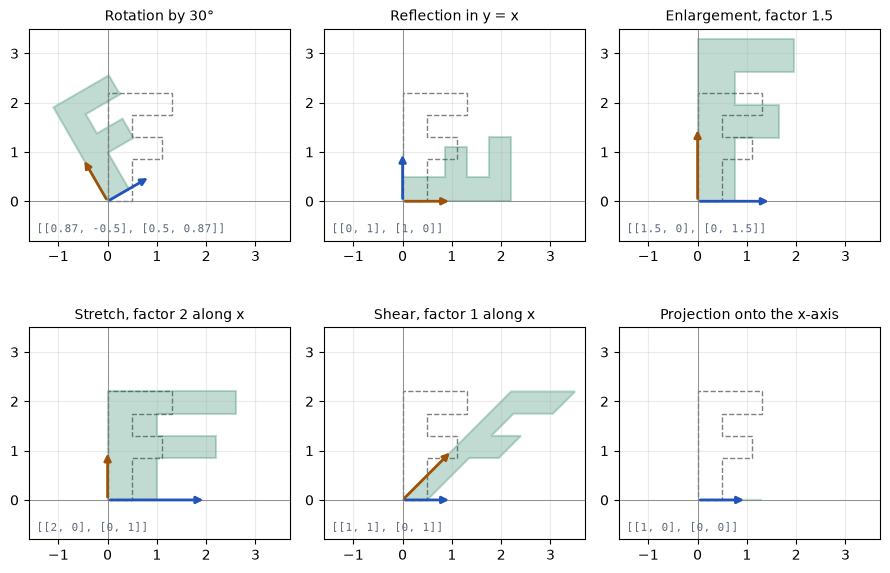

In [1]:
import numpy as np
import matplotlib.pyplot as plt

F = np.array([[0, 0], [0.5, 0], [0.5, 0.85], [1.1, 0.85], [1.1, 1.3], [0.5, 1.3],
              [0.5, 1.75], [1.3, 1.75], [1.3, 2.2], [0, 2.2]]).T
c, s = np.cos(np.pi / 6), np.sin(np.pi / 6)
gallery = [
    ("Rotation by 30°", np.array([[c, -s], [s, c]])),
    ("Reflection in y = x", np.array([[0, 1], [1, 0]])),
    ("Enlargement, factor 1.5", np.array([[1.5, 0], [0, 1.5]])),
    ("Stretch, factor 2 along x", np.array([[2, 0], [0, 1]])),
    ("Shear, factor 1 along x", np.array([[1, 1], [0, 1]])),
    ("Projection onto the x-axis", np.array([[1, 0], [0, 0]])),
]
fig, axes = plt.subplots(2, 3, figsize=(9, 6.2))
for ax, (title, M) in zip(axes.flat, gallery):
    G = M @ F
    ax.fill(*F, fill=False, ls="--", ec="grey", lw=1)
    ax.fill(*G, color="#0a7050", alpha=0.25, ec="#0a7050", lw=1.5)
    for col, colour in [(M[:, 0], "#2153b8"), (M[:, 1], "#9c5208")]:
        ax.annotate("", xy=col, xytext=(0, 0),
                    arrowprops=dict(arrowstyle="-|>", color=colour, lw=2))
    ax.set_title(title, fontsize=10)
    ax.text(0.03, 0.04, "[[{:.2g}, {:.2g}], [{:.2g}, {:.2g}]]".format(*M.flat),
            transform=ax.transAxes, fontsize=8, family="monospace", color="#5e6b7c")
    ax.set_xlim(-1.6, 3.7); ax.set_ylim(-0.8, 3.5)
    ax.set_aspect("equal"); ax.grid(alpha=0.25)
    ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
plt.tight_layout()
plt.show()

## In code

To transform a whole shape at once, store its points as the **columns** of a matrix. Then one multiplication moves every point, because column $j$ of $\mathbf{A}\mathbf{P}$ is $\mathbf{A}$ times column $j$ of $\mathbf{P}$.

[[0.  1.  1.5 0.5]
 [0.  0.  1.  1. ]]


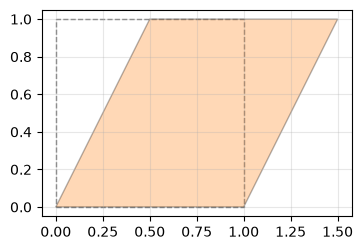

In [2]:
import numpy as np
import matplotlib.pyplot as plt

P = np.array([[0, 1, 1, 0],          # x-coordinates of the corners
              [0, 0, 1, 1]])         # y-coordinates
A = np.array([[1, 0.5],
              [0, 1]])               # shear, factor 0.5
Q = A @ P                            # transform every corner at once
print(Q)

fig, ax = plt.subplots(figsize=(4, 3))
ax.fill(*P, fill=False, ls="--", ec="grey")
ax.fill(*Q, alpha=0.3, ec="black")
ax.set_aspect("equal"); ax.grid(alpha=0.3)
plt.show()

## Exercises

The code exercises from the [end of the chapter](https://trgoodale.github.io/matrix-book/part-1/04-transformations.html#sec-transformations-exercises). Worked solutions are in the notebook `solutions-part-1.ipynb`, and in the [book's solutions](https://trgoodale.github.io/matrix-book/appendices/solutions-1.html#sec-solutions-transformations).

### Exercise 7

Apply the rotation $\mathbf{R}(\theta)$ to the F shape (corner coordinates are in the code for [Figure 4.1](https://trgoodale.github.io/matrix-book/part-1/04-transformations.html#fig-transformation-gallery)) for $\theta = 0°, 45°, 90°, \dots, 315°$, and plot all eight images on one set of axes.

In [3]:
# Your code here